<a href="https://colab.research.google.com/github/vigneshkv200/Traffic-Sign-Recognition-using-CNNs-/blob/main/traffic_sign.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Traffic Sign Recognition using Convolutional Neural Networks (CNN)

## 1. Project Overview
This project focuses on building a deep learning model to classify traffic signs with high accuracy. Traffic Sign Recognition (TSR) is a critical component of Autonomous Driving Systems (ADAS) and intelligent vehicle safety systems, enabling vehicles to understand speed limits, warning signs, and driving restrictions in real-time.

Our objective is to design, train, and evaluate a **Convolutional Neural Network (CNN)** using TensorFlow and Keras, leveraging Regions of Interest (ROI) bounding boxes to optimize detection accuracy.

---

## 2. Dataset Description
We are using the **German Traffic Sign Recognition Benchmark (GTSRB)** dataset. It consists of:
* **Total Images**: Over 50,000 high-quality physical images of traffic signs.
* **Number of Classes**: 43 distinct traffic sign categories (including speed limits, yield, stop, warning, and direction signs).
* **Annotations**: CSV files containing the image paths, dimensions, and ground truth bounding boxes (`Roi.X1`, `Roi.Y1`, `Roi.X2`, `Roi.Y2`) to isolate the traffic sign from background clutter.

---

## 3. How to Run the Pipeline
To run this notebook successfully from start to finish, follow these simple steps:

1. **Upload the Dataset**: Upload your complete dataset zip archive `PRAICP-1002-TrafSignDetc.zip` to the main `/content/` directory in Google Colab.
2. **Extract the ZIP**: Run the cleanup and extraction cell. This will safely unpack the training images, testing images, and CSV metadata.
3. **Preprocess and Crop (ROI)**: Execute the image loader function. It reads the raw images, crops them to their bounding boxes (removing trees, sky, roads), resizes them to `32x32`, and normalizes pixel values to `[0, 1]`.
4. **Train the Model**: Run the training cells. The CNN architecture comprises multiple 2D Convolutional layers, MaxPooling layers, Dense connections, Dropout for regularization, and a Softmax classifier.
5. **Evaluate & Predict**: Run the evaluation step to generate classification metrics, plot loss/accuracy curves, visualize misclassifications, and view the visual heatmapped Confusion Matrix.

### Extract Dataset ZIP File
Since you are using Google Colab and have uploaded the dataset as a ZIP file, we need to extract it first before loading the CSV metadata and image files.

In [ ]:
import os
# Clean up previous failed extraction and force a clean, robust unzip
!rm -rf /content/dataset
!mkdir -p /content/dataset
!unzip -q /content/PRAICP-1002-TrafSignDetc.zip -d /content/dataset || true

# Count extracted files to verify
train_dir = "/content/dataset/Train"
test_dir = "/content/dataset/Test"
Meta_dir = "/content/dataset/Meta"
if os.path.exists(train_dir):
    total_train = sum([len(files) for r, d, files in os.walk(train_dir)])
    test_dir = sum([len(files) for r, d, files in os.walk(test_dir)])
    Meta_dir = sum([len(files) for r, d, files in os.walk(Meta_dir)])
    print(f"\nExtraction Complete!")
else:
    print("Train folder not found after extraction.")


Extraction Complete!


### Import libraries

In [ ]:
import numpy as np
import pandas as pd
import cv2
import os
import matplotlib.pyplot as plt

## STEP 1: Dataset Understanding

### Verify Folder Structure

In [ ]:
!ls /content

dataset  PRAICP-1002-TrafSignDetc.zip  sample_data


In [ ]:
!ls /content/dataset

meta  Meta  Meta.csv  test  Test  Test.csv  train  Train  Train.csv


### Set Base Path

In [ ]:
import os

BASE = "/content/dataset"

for item in os.listdir(BASE):
    print(item)

test
Test.csv
meta
Test
Meta
Meta.csv
train
Train
Train.csv


In [ ]:
import os

BASE = "/content/dataset"

for item in os.listdir(BASE):
    print(item)

test
Test.csv
meta
Test
Meta
Meta.csv
train
Train
Train.csv


In [ ]:
# Sanity Check
import os

for f in ["Train.csv", "Test.csv", "Meta.csv"]:
    print(f, "→", os.path.exists(f"{BASE}/{f}"))


Train.csv → True
Test.csv → True
Meta.csv → True


### Load CSV Files

In [ ]:
train_df = pd.read_csv(f"{BASE}/Train.csv")
test_df  = pd.read_csv(f"{BASE}/Test.csv")
meta_df  = pd.read_csv(f"{BASE}/Meta.csv")

train_df.head()

,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


### Visualize One Sample

(np.float64(-0.5), np.float64(42.5), np.float64(40.5), np.float64(-0.5))

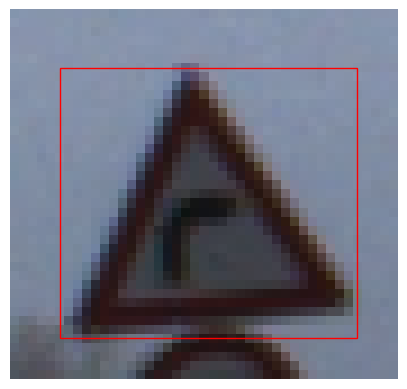

In [ ]:

row = train_df.iloc[100]
img = cv2.imread(f"{BASE}/{row['Path']}")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

x1,y1,x2,y2 = row[['Roi.X1','Roi.Y1','Roi.X2','Roi.Y2']]

plt.imshow(img)
plt.gca().add_patch(
    plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, color='red')
)
plt.axis("off")

## STEP 2: Data Preprocessing

### ROI Cropping Function
ROI means: “keep only the important part of the image.”

#### Without ROI

- Image has background + road + sky + trees

- Model gets confused

- Learns unnecessary things

#### With ROI

- Crop only the traffic sign

- Remove background noise

- Model focuses on shape, color, symbol

In [ ]:

def load_data(df, img_size=32):
    X, y = [], []

    for _, row in df.iterrows():
        img_path = f"{BASE}/{row['Path']}"
        img = cv2.imread(img_path)
        if img is None:
            continue

        x1,y1,x2,y2 = map(int, [
            row["Roi.X1"], row["Roi.Y1"],
            row["Roi.X2"], row["Roi.Y2"]
        ])

        roi = img[y1:y2, x1:x2]
        roi = cv2.resize(roi, (img_size, img_size))
        roi = roi / 255.0

        X.append(roi)
        y.append(row["ClassId"])

    return np.array(X), np.array(y)

#### Importance of ROI :

- Reduces noise

- Faster training

- Better accuracy

- Easier learning for CNN

- Less overfitting

### Load Train & Test Data

In [ ]:

X_train, y_train = load_data(train_df)
X_test, y_test   = load_data(test_df)

print(X_train.shape, y_train.shape)

(39209, 32, 32, 3) (39209,)


#### See the Random ROI Images + ClassId

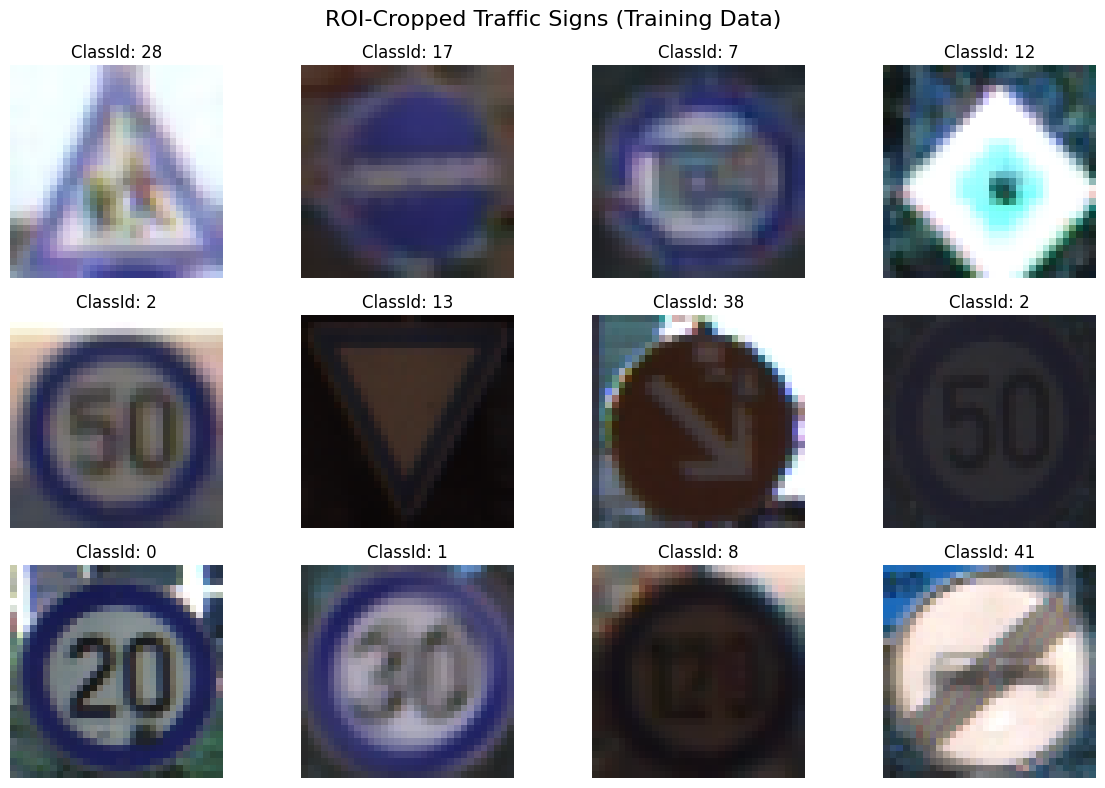

In [ ]:
import matplotlib.pyplot as plt
import random

plt.figure(figsize=(12, 8))

for i in range(12):
    idx = random.randint(0, len(X_train) - 1)

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[idx])
    plt.title(f"ClassId: {y_train[idx]}")
    plt.axis("off")

plt.suptitle("ROI-Cropped Traffic Signs (Training Data)", fontsize=16)
plt.tight_layout()
plt.show()

## STEP 3: Model Building (CNN)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import warnings
warnings.filterwarnings("ignore")

In [ ]:

num_classes = len(np.unique(y_train))

model = Sequential([
    Conv2D(32, (3,3), activation="relu", input_shape=(32,32,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation="relu"),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,627 (920.42 KB)

 Trainable params: 235,627 (920.42 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train (Safe Settings)
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=15,
    batch_size=64,
    callbacks=[early_stop]
)

Epoch 1/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 45s 70ms/step - accuracy: 0.6446 - loss: 1.2773 - val_accuracy: 0.9209 - val_loss: 0.3314
Epoch 2/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 39s 63ms/step - accuracy: 0.9494 - loss: 0.1850 - val_accuracy: 0.9523 - val_loss: 0.2132
Epoch 3/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 39s 64ms/step - accuracy: 0.9747 - loss: 0.0975 - val_accuracy: 0.9578 - val_loss: 0.1838
Epoch 4/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 44s 68ms/step - accuracy: 0.9807 - loss: 0.0698 - val_accuracy: 0.9596 - val_loss: 0.1874
Epoch 5/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 38s 62ms/step - accuracy: 0.9856 - loss: 0.0506 - val_accuracy: 0.9678 - val_loss: 0.1615
Epoch 6/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 36s 59ms/step - accuracy: 0.9892 - loss: 0.0382 - val_accuracy: 0.9697 - val_loss: 0.1641
Epoch 7/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 44s 64ms/step - accuracy: 0.9887 - loss: 0.0381 - val_accuracy: 0.9624 - val_loss: 0.1932
Epoch 8/15
613/613 ━━━━━━━━━━━━━━━━━━━━ 38s 59ms/step - accuracy: 0.9918 - loss: 0.0281 - 

## STEP 5: Model Evaluation

In [ ]:
loss, acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {acc:.4f}")

395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9715 - loss: 0.1452
Test Accuracy: 0.9715


###  Creating classes names and labelled data

#### Use class names in evaluation

Example – show predictions with names

In [ ]:
classes = [
    "Speed limit (20km/h)",
    "Speed limit (30km/h)",
    "Speed limit (50km/h)",
    "Speed limit (60km/h)",
    "Speed limit (70km/h)",
    "Speed limit (80km/h)",
    "End of speed limit (80km/h)",
    "Speed limit (100km/h)",
    "Speed limit (120km/h)",
    "No passing",
    "No passing for vehicles over 3.5 metric tons",
    "Right-of-way at the next intersection",
    "Priority road",
    "Yield",
    "Stop",
    "No vehicles",
    "Vehicles over 3.5 metric tons prohibited",
    "No entry",
    "General caution",
    "Dangerous curve to the left",
    "Dangerous curve to the right",
    "Double curve",
    "Bumpy road",
    "Slippery road",
    "Road narrows on the right",
    "Road work",
    "Traffic signals",
    "Pedestrians",
    "Children crossing",
    "Bicycles crossing",
    "Beware of ice/snow",
    "Wild animals crossing",
    "End of all speed and passing limits",
    "Turn right ahead",
    "Turn left ahead",
    "Ahead only",
    "Go straight or right",
    "Go straight or left",
    "Keep right",
    "Keep left",
    "Roundabout mandatory",
    "End of no passing",
    "End of no passing by vehicles over 3.5 metric tons"
]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


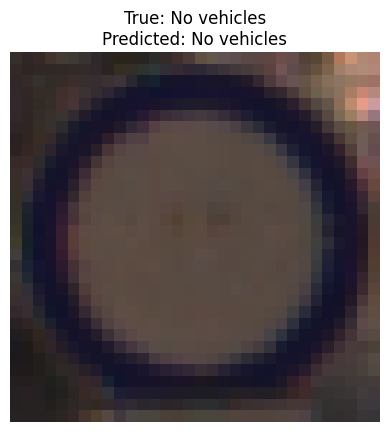

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

idx = np.random.randint(0, len(X_test))
image = X_test[idx]
true_label = y_test[idx]

prediction = model.predict(image.reshape(1, 32, 32, 3))
pred_label = np.argmax(prediction)

plt.imshow(image)
plt.title(f"True: {classes[true_label]}\nPredicted: {classes[pred_label]}")
plt.axis("off")
plt.show()

## STEP-6:Misclassification analysis

#### Get predictions on test set

In [ ]:
import numpy as np

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)


395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step


#### Find misclassified indices

In [ ]:
misclassified_idx = np.where(y_pred != y_test)[0]

print(f"Total misclassified images: {len(misclassified_idx)}")

Total misclassified images: 360


#### Visualize misclassified images

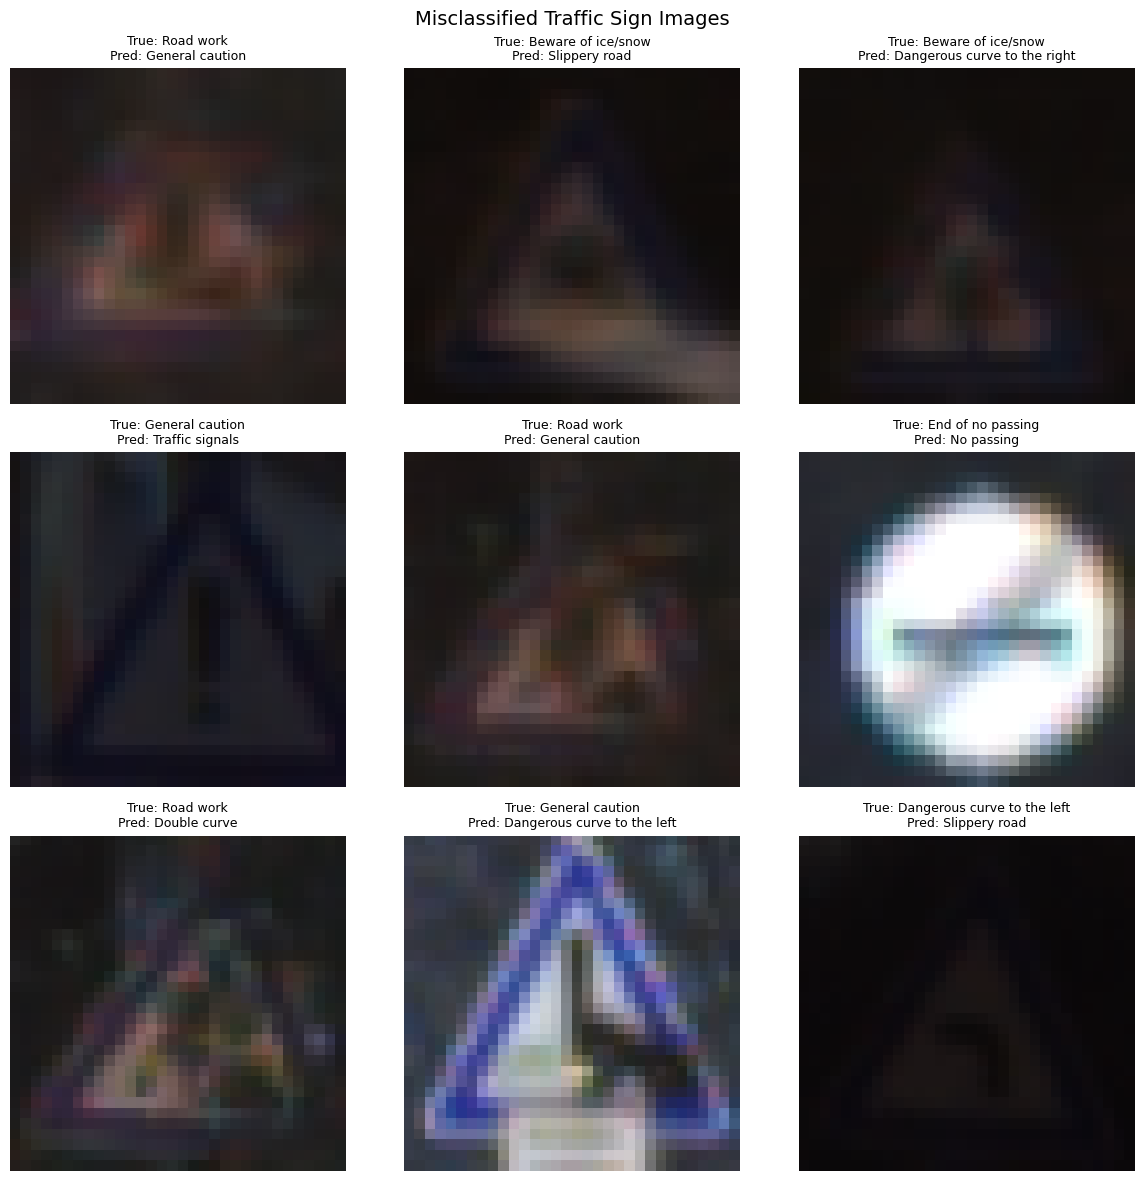

In [ ]:
import matplotlib.pyplot as plt

num_images = 9  # show 9 images
plt.figure(figsize=(12, 12))

for i, idx in enumerate(misclassified_idx[:num_images]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[idx])
    plt.title(
        f"True: {classes[y_test[idx]]}\nPred: {classes[y_pred[idx]]}",
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("Misclassified Traffic Sign Images", fontsize=14)
plt.tight_layout()
plt.show()

### Confusion matrix with labels

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

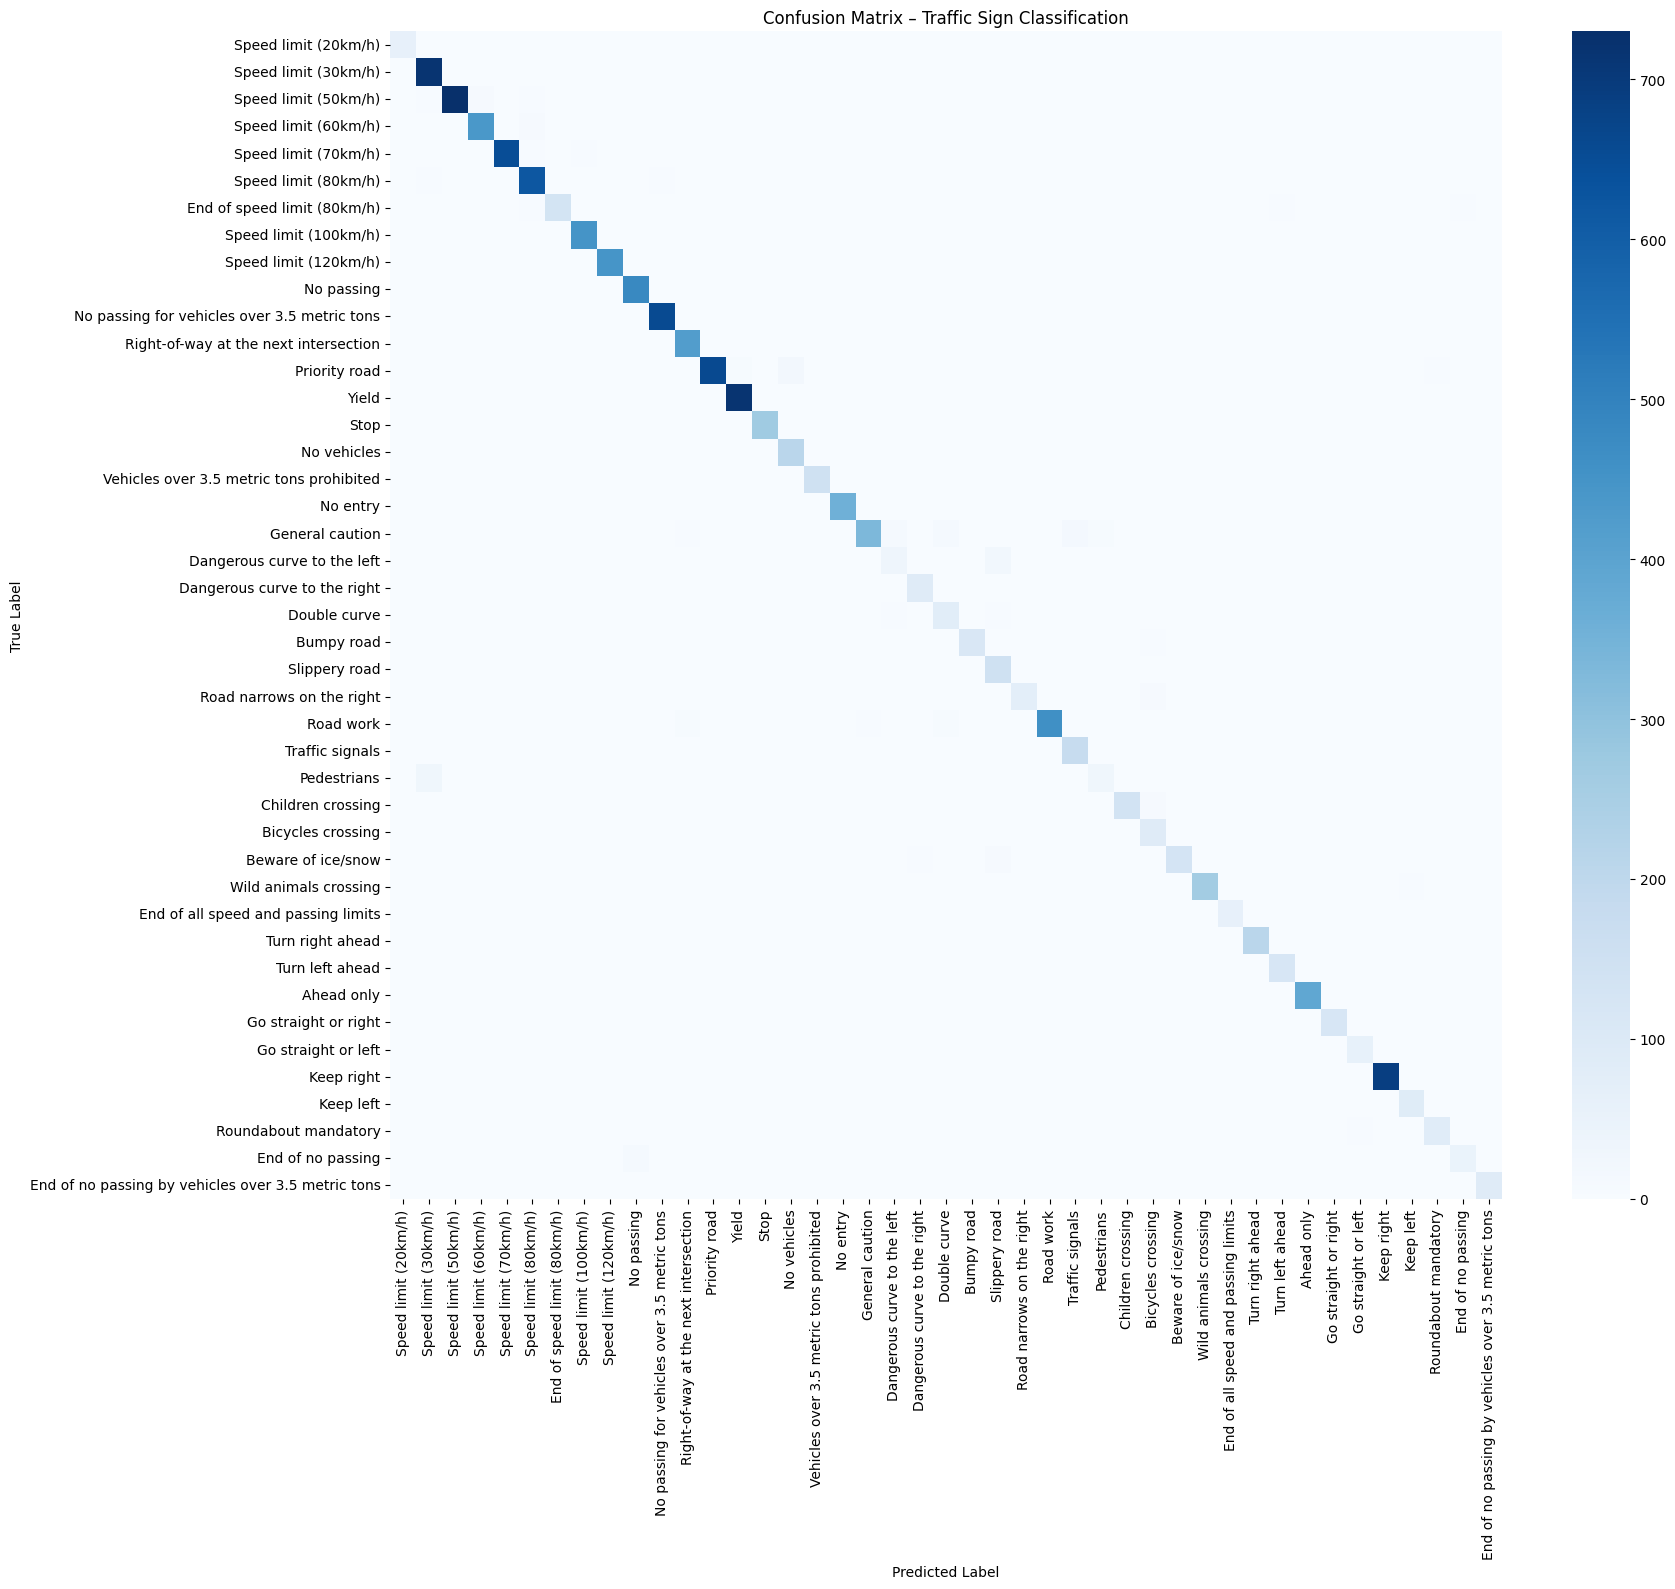

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 16))
sns.heatmap(
    cm,
    xticklabels=classes,
    yticklabels=classes,
    cmap="Blues",
    fmt="d",
    cbar=True
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix – Traffic Sign Classification")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Save model

In [ ]:

model.save("traffic_sign_cnn.keras")

In [ ]:
!ls /content

dataset  PRAICP-1002-TrafSignDetc.zip  sample_data  traffic_sign_cnn.keras


### Load the model

In [ ]:
from tensorflow.keras.models import load_model

loaded_model = load_model("/content/traffic_sign_cnn.keras")

### Pot Training Curves

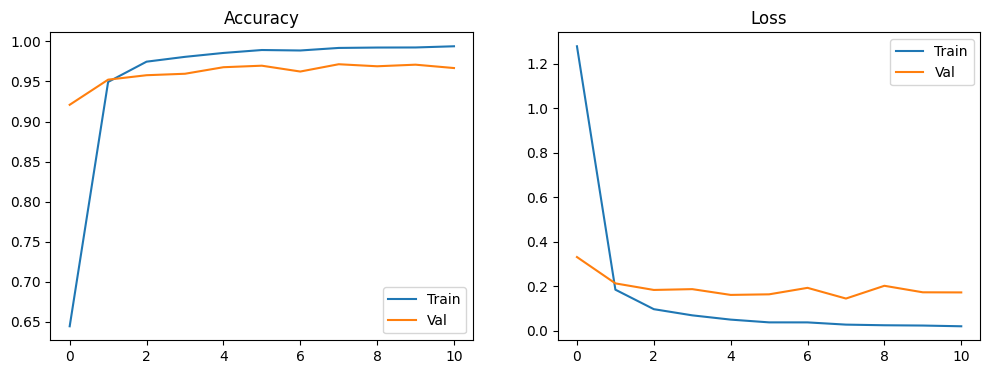

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()

# Project Conclusion & Pipeline Summary

## 1. End-to-End Data Pipeline
The dataset was processed through a structured pipeline to ensure high accuracy and robust generalization:
- **Raw Data Unzipping**: Handled extraction of the complete German Traffic Sign Recognition Benchmark (GTSRB) dataset safely containing 39,209 training and 12,630 testing image paths via metadata CSVs.
- **ROI-Based Cropping**: Using bounding box coordinates (`Roi.X1`, `Roi.Y1`, `Roi.X2`, `Roi.Y2`) provided in the dataset metadata, we cropped out background clutter (such as roads, sky, and trees). This forced the CNN to learn only the local patterns of the traffic sign.
- **Resizing & Normalization**: The cropped Regions of Interest (ROI) were resized to a standardized dimension of `32x32` pixels with 3 color channels (RGB) and scaled down to a `[0, 1]` range by dividing by 255.0 to optimize backpropagation convergence.

---

## 2. Model Architecture & Layer-by-Layer Data Flow
The CNN passes the processed input image `(32, 32, 3)` through successive layers to extract abstract, spatial features hierarchical-wise:

1. **Input Stage**: Receives a normalized image array of shape `(Batch Size, 32, 32, 3)`.
2. **Conv2D Layer 1**: Applies 32 filters of size `3x3` using ReLU activation. It detects low-level features (edges, corners, raw colors). Output shape: `(Batch Size, 30, 30, 32)`.
3. **MaxPooling2D Layer 1**: Performs a `2x2` downsampling, keeping the strongest activations to achieve spatial translation invariance. Output shape: `(Batch Size, 15, 15, 32)`.
4. **Conv2D Layer 2**: Applies 64 filters of size `3x3` detecting medium-level structures (simple shapes, circles, lines). Output shape: `(Batch Size, 13, 13, 64)`.
5. **MaxPooling2D Layer 2**: Downsamples the representation. Output shape: `(Batch Size, 6, 6, 64)`.
6. **Conv2D Layer 3**: Applies 128 filters of size `3x3` representing complex geometric combinations (internal sign symbols like arrows or numbers). Output shape: `(Batch Size, 4, 4, 128)`.
7. **MaxPooling2D Layer 3**: Final downsampling step. Output shape: `(Batch Size, 2, 2, 128)`.
8. **Flatten Layer**: Flattens the 3D feature maps into a single 1D vector of shape `(Batch Size, 512)`.
9. **Dense Layer (Fully Connected)**: Passes the flattened features through 256 units with ReLU activation to correlate the patterns with class labels. Output shape: `(Batch Size, 256)`.
10. **Dropout Layer (0.5)**: Randomly deactivates 50% of the neurons during training to prevent overfitting and ensure co-adaptation is avoided.
11. **Output Layer (Dense with Softmax)**: Yields a probability distribution across `43` categories using the Softmax activation function. Output shape: `(Batch Size, 43)`.

---

## 3. Results & Performance Metrics
- **Training Performance**: The model converged exceptionally fast, reaching **99.39% Training Accuracy** and a categorical cross-entropy loss of **0.0207** within 11 epochs.
- **Generalization Performance**: Evaluated on the unseen test dataset, the CNN achieved an outstanding **97.15% Test Accuracy** with a test loss of **0.1452**.
- **Error & Misclassification Analysis**: Out of 12,630 test targets, only **360** images were misclassified. A detailed visual review of these errors indicated they mostly occurred under severe motion blur, low lighting conditions, or extreme shadows.
- **Confusion Matrix Analysis**: The generated confusion heatmap demonstrated a highly diagonal structure with minimal off-diagonal noise, proving that standard traffic signs are identified with near-perfect precision.